In [2]:
import pandas as pd
import numpy as np

train_path = "data/train.csv"
test_path = "data/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (1460, 81)
Testing data shape: (1459, 80)


In [3]:
print("Training Dataset Info:")
train_df.info()

print("\nFirst 5 Rows:")
display(train_df.head())

Training Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
missing_values = train_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Columns with missing values:")
display(missing_values)

Columns with missing values:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [5]:
print("SalePrice Statistics:")
display(train_df["SalePrice"].describe())

print("\nUnique SalePrice values:", train_df["SalePrice"].nunique())

SalePrice Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


Unique SalePrice values: 663


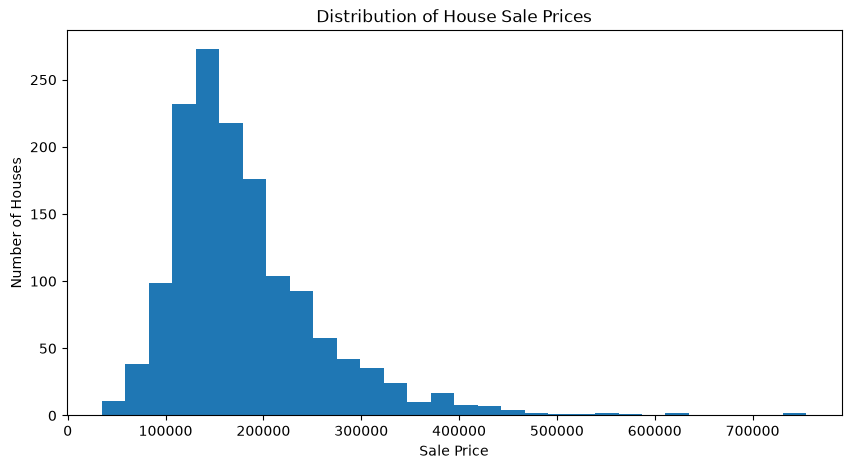

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(train_df["SalePrice"], bins=30)
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Sale Prices")
plt.show()

In [7]:
correlation = train_df.select_dtypes(include=["int64", "float64"]).corr()["SalePrice"]

correlation = correlation.sort_values(ascending=False)

display(correlation.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

In [8]:
train_df = train_df.drop(columns=["Id"])
test_df = test_df.drop(columns=["Id"])

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (1460, 80)
Testing shape: (1459, 79)


In [9]:
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 79)
Target shape: (1460,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (1168, 79)
X_valid: (292, 79)
y_train: (1168,)
y_valid: (292,)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


In [12]:
from sklearn.pipeline import Pipeline

In [13]:
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)

Processed training shape: (1168, 285)
Processed validation shape: (292, 285)


In [14]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

linear_predictions = linear_model.predict(X_valid_processed)

print("First 10 predictions:")
print(linear_predictions[:10])

First 10 predictions:
[151971.20051183 356441.14089892  95590.88330007 177919.63763369
 342171.21147719  59615.31585659 253448.9505881  153388.03759418
  53796.95852136 149553.68215884]


In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

linear_rmse = np.sqrt(mean_squared_error(y_valid, linear_predictions))
linear_mae = mean_absolute_error(y_valid, linear_predictions)
linear_r2 = r2_score(y_valid, linear_predictions)

print("Linear Regression Performance")
print("-" * 35)
print(f"RMSE: {linear_rmse:.2f}")
print(f"MAE:  {linear_mae:.2f}")
print(f"R²:   {linear_r2:.4f}")

Linear Regression Performance
-----------------------------------
RMSE: 31294.99
MAE:  20466.13
R²:   0.8723


In [16]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_valid_processed)

print("First 10 predictions:")
print(rf_predictions[:10])

First 10 predictions:
[140689.66666667 324020.6        116395.44       153197.76333333
 321560.87666667  85867.16666667 210936.61333333 152330.92666667
  85825.33       128622.29      ]


In [17]:
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))
rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_r2 = r2_score(y_valid, rf_predictions)

print("Random Forest Performance")
print("-" * 35)
print(f"RMSE: {rf_rmse:.2f}")
print(f"MAE:  {rf_mae:.2f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Performance
-----------------------------------
RMSE: 28376.65
MAE:  17350.76
R²:   0.8950


In [18]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed.toarray(), y_train)

gb_predictions = gb_model.predict(X_valid_processed.toarray())

print("First 10 predictions:")
print(gb_predictions[:10])

First 10 predictions:
[146763.88744921 337840.66183202 118599.28828179 149109.91568974
 336517.72880229  82378.51321123 224818.11315375 138833.7719046
  82011.89402449 134349.38647615]


In [19]:
gb_rmse = np.sqrt(mean_squared_error(y_valid, gb_predictions))
gb_mae = mean_absolute_error(y_valid, gb_predictions)
gb_r2 = r2_score(y_valid, gb_predictions)

print("Gradient Boosting Performance")
print("-" * 35)
print(f"RMSE: {gb_rmse:.2f}")
print(f"MAE:  {gb_mae:.2f}")
print(f"R²:   {gb_r2:.4f}")

Gradient Boosting Performance
-----------------------------------
RMSE: 27784.52
MAE:  16624.09
R²:   0.8994


In [20]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "R2": [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

results = results.sort_values("RMSE")

display(results)

,Model,RMSE,MAE,R2
2,Gradient Boosting,27784.522754,16624.086369,0.899355
1,Random Forest,28376.645804,17350.759064,0.895020
0,Linear Regression,31294.990974,20466.133696,0.872316


In [21]:
import joblib

joblib.dump(gb_model, "house_price_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model and preprocessor saved successfully.")

Model and preprocessor saved successfully.


In [22]:
sample_index = 0

sample_house = X_valid.iloc[[sample_index]]
actual_price = y_valid.iloc[sample_index]

sample_processed = preprocessor.transform(sample_house)

predicted_price = gb_model.predict(sample_processed.toarray())[0]

print(f"Actual Price:    ${actual_price:,.2f}")
print(f"Predicted Price: ${predicted_price:,.2f}")

Actual Price:    $154,500.00
Predicted Price: $146,763.89


In [23]:
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nSalePrice statistics:")
print(train_df["SalePrice"].describe())

Training data shape: (1460, 80)
Testing data shape: (1459, 79)

SalePrice statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


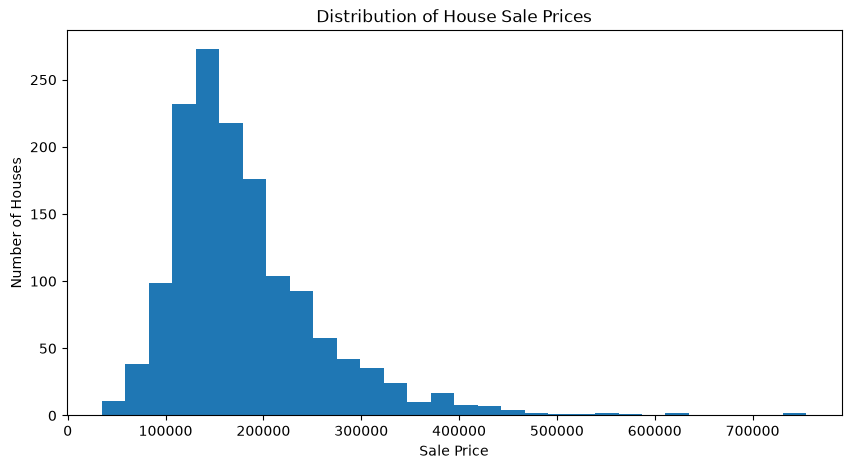

In [24]:
plt.figure(figsize=(10, 5))
plt.hist(train_df["SalePrice"], bins=30)
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Sale Prices")
plt.show()

In [25]:
numeric_df = train_df.select_dtypes(include=["int64", "float64"])

correlations = numeric_df.corr()["SalePrice"].sort_values(ascending=False)

print(correlations.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)

Processed training shape: (1168, 285)
Processed validation shape: (292, 285)


In [27]:
import joblib

joblib.dump(gb_model, "house_price_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model saved as: house_price_model.pkl")
print("Preprocessor saved as: preprocessor.pkl")

Model saved as: house_price_model.pkl
Preprocessor saved as: preprocessor.pkl


In [28]:
sample_index = 0

sample_house = X_valid.iloc[[sample_index]]
actual_price = y_valid.iloc[sample_index]

sample_processed = preprocessor.transform(sample_house)
predicted_price = gb_model.predict(sample_processed.toarray())[0]

print(f"Actual Price: ${actual_price:,.2f}")
print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Absolute Difference: ${abs(actual_price - predicted_price):,.2f}")

Actual Price: $154,500.00
Predicted Price: $146,763.89
Absolute Difference: $7,736.11
